In [1]:
# ========== 导入标准库 ==========
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ========== 导入强化学习相关库 ==========
import gymnasium as gym
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv

# ========== 将 src 目录添加到 Python 搜索路径 ==========
# 假设 Notebook 在 notebooks/ 文件夹下，src 与 notebooks 同级
# 如果 Notebook 在项目根目录下，使用 './src'
sys.path.append('../src')   # 根据实际路径调整，若报错可改为 './src' 或绝对路径

# 从自定义模块导入环境类
from environment import PortfolioTradingEnv

print("✅ 导入成功")

✅ 导入成功


In [2]:
# ========== 使用绝对路径加载价格数据 ==========
# 请根据你的实际文件位置修改路径
prices = pd.read_csv('D:/desktop/QuantProject2/data/hs300_prices.csv', index_col=0, parse_dates=True)

print("价格矩阵形状:", prices.shape)   # 应为 (727, 297)
print("前3行前5列：")
print(prices.iloc[:3, :5])

价格矩阵形状: (727, 297)
前3行前5列：
             sh_600000   sh_600009  sh_600010  sh_600011  sh_600015
date                                                               
2021-01-04   99.924569  200.879342   8.476400  16.534827  21.838726
2021-01-05   99.821447  200.386800   8.404566  16.167386  22.014561
2021-01-06  101.265146  200.879342   8.404566  16.277619  22.049728


In [3]:
# 只用训练期数据选股

# ========== 修正：只用训练期（2021-2022）数据选股 ==========
train_start = '2021-01-04'
train_end   = '2022-12-30'
test_start  = '2023-01-03'
test_end    = '2023-12-29'

# 只用训练期数据判断完整性，绝不使用测试期信息
prices_train_only = prices.loc[train_start:train_end]
completeness = prices_train_only.notna().sum() / len(prices_train_only)

# 取数据最完整的20只
selected_stocks = completeness.sort_values(ascending=False).head(20).index.tolist()
print(f"选中的股票数量: {len(selected_stocks)}")
print("股票代码:", selected_stocks)

# 提取选中股票的价格（全期，但选股只用了训练期信息）
prices_selected = prices.loc[train_start:test_end, selected_stocks]

# 划分训练集和测试集
train_prices = prices_selected.loc[train_start:train_end]
test_prices  = prices_selected.loc[test_start:test_end]

print("训练集形状:", train_prices.shape)
print("测试集形状:", test_prices.shape)

选中的股票数量: 20
股票代码: ['sz_302132', 'sh_600000', 'sh_600009', 'sh_600010', 'sh_600011', 'sh_600015', 'sh_600016', 'sh_600018', 'sh_600019', 'sz_300476', 'sz_300450', 'sz_300442', 'sz_300433', 'sz_300418', 'sz_300413', 'sz_300408', 'sz_300394', 'sz_300316', 'sz_300308', 'sz_300274']
训练集形状: (485, 20)
测试集形状: (242, 20)


In [4]:
# ========== 修正选股后，重新计算等权基准 ==========
def annual_return(values):
    total_ret = values[-1] / values[0] - 1
    years = len(values) / 252
    return (1 + total_ret) ** (1/years) - 1

benchmark_new = (1 + test_prices.pct_change().fillna(0).mean(axis=1)).cumprod()
benchmark_annual_new = annual_return(benchmark_new.values)
print(f"修正后等权基准年化收益: {benchmark_annual_new:.2%}")

修正后等权基准年化收益: 32.46%


In [5]:
# 创建训练环境（向量化）

# ========== 定义环境工厂函数 ==========
def make_train_env():
    """为 DummyVecEnv 创建训练环境的函数"""
    return PortfolioTradingEnv(train_prices)

# 使用 DummyVecEnv 包装，使 stable-baselines3 能使用
train_env = DummyVecEnv([make_train_env])

# 测试环境是否能正确重置
obs = train_env.reset()
print("向量化环境观测形状:", obs.shape)   # 应为 (1, 81) 因为 4*20+1=81

向量化环境观测形状: (1, 81)


In [6]:
# ========== 创建 PPO 模型 ==========
model = PPO(
    policy="MlpPolicy",           # 使用多层感知机策略网络
    env=train_env,                # 训练环境
    learning_rate=3e-4,           # 学习率
    n_steps=2048,                 # 每次收集的数据步数
    batch_size=64,                # 小批量大小
    n_epochs=10,                  # 每轮数据重复训练次数
    gamma=0.99,                   # 折扣因子
    gae_lambda=0.95,              # GAE lambda
    clip_range=0.2,               # PPO 裁剪范围
    verbose=1,                    # 打印训练日志
    seed=42                       # 随机种子
)

# ========== 开始训练 ==========
total_timesteps = 100_000   # 训练总步数（可调整）
model.learn(total_timesteps=total_timesteps)

# ========== 保存模型 ==========
model.save("rl_portfolio_ppo")
print("✅ 模型训练完成并已保存为 rl_portfolio_ppo.zip")

Using cpu device
-----------------------------
| time/              |      |
|    fps             | 1451 |
|    iterations      | 1    |
|    time_elapsed    | 1    |
|    total_timesteps | 2048 |
-----------------------------
-----------------------------------------
| time/                   |             |
|    fps                  | 1157        |
|    iterations           | 2           |
|    time_elapsed         | 3           |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.012785699 |
|    clip_fraction        | 0.118       |
|    clip_range           | 0.2         |
|    entropy_loss         | -29.7       |
|    explained_variance   | -1.41       |
|    learning_rate        | 0.0003      |
|    loss                 | -0.0587     |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0325     |
|    std                  | 0.997       |
|    value_loss           | 0.00309     |
-----------------

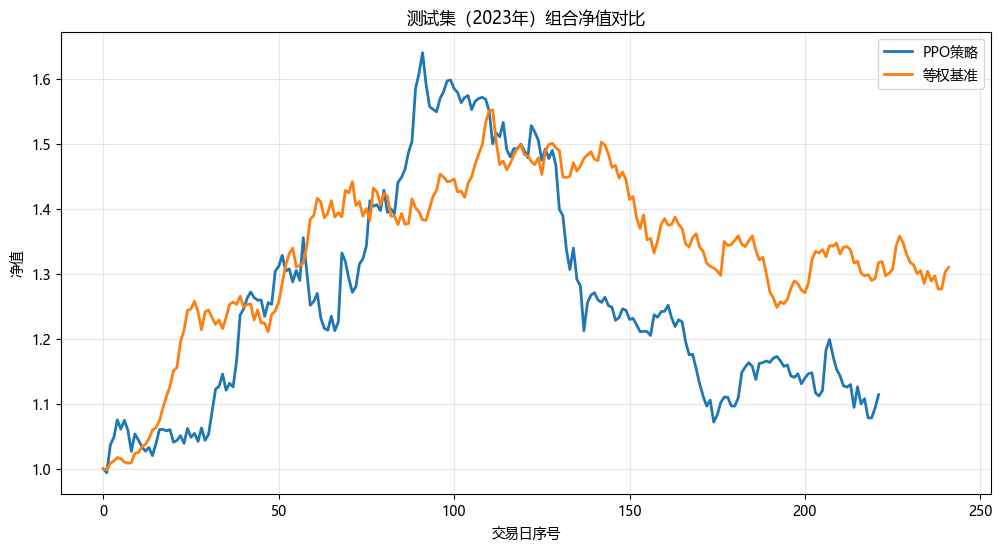

In [7]:
# 在测试集上回测

# ========== 创建测试环境 ==========
test_env = PortfolioTradingEnv(test_prices)

# ========== 使用训练好的模型进行回测 ==========
obs, _ = test_env.reset()
done = False
portfolio_values = [1.0]   # 初始净值

while not done:
    # 使用确定性策略（不探索），输出动作
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, done, truncated, info = test_env.step(action)
    portfolio_values.append(test_env.portfolio_value)

# ========== 计算基准：等权持有 ==========
benchmark = (1 + test_prices.pct_change().fillna(0).mean(axis=1)).cumprod()

# ========== 绘制净值对比图 ==========
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False
plt.figure(figsize=(12,6))
plt.plot(portfolio_values, label='PPO策略', linewidth=2)
plt.plot(benchmark.values, label='等权基准', linewidth=2)
plt.title('测试集（2023年）组合净值对比')
plt.xlabel('交易日序号')
plt.ylabel('净值')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [8]:
# 计算绩效指标

# ========== 计算策略和基准的日收益率 ==========
strategy_ret = pd.Series(portfolio_values).pct_change().dropna()
benchmark_ret = benchmark.pct_change().dropna()

# ========== 年化收益率 ==========
def annual_return(values):
    total_ret = values[-1] / values[0] - 1
    years = len(values) / 252
    return (1 + total_ret) ** (1/years) - 1

strategy_annual = annual_return(portfolio_values)
benchmark_annual = annual_return(benchmark.values)

# ========== 夏普比率（假设无风险利率=0） ==========
strategy_sharpe = strategy_ret.mean() / strategy_ret.std() * np.sqrt(252)
benchmark_sharpe = benchmark_ret.mean() / benchmark_ret.std() * np.sqrt(252)

# ========== 最大回撤 ==========
def max_drawdown(values):
    cummax = pd.Series(values).cummax()
    drawdown = (pd.Series(values) - cummax) / cummax
    return drawdown.min()

strategy_mdd = max_drawdown(portfolio_values)
benchmark_mdd = max_drawdown(benchmark.values)

# ========== 汇总打印 ==========
print(f"策略年化收益: {strategy_annual:.2%}")
print(f"基准年化收益: {benchmark_annual:.2%}")
print(f"策略夏普比率: {strategy_sharpe:.2f}")
print(f"基准夏普比率: {benchmark_sharpe:.2f}")
print(f"策略最大回撤: {strategy_mdd:.2%}")
print(f"基准最大回撤: {benchmark_mdd:.2%}")

策略年化收益: 13.04%
基准年化收益: 32.46%
策略夏普比率: 0.56
基准夏普比率: 1.51
策略最大回撤: -34.64%
基准最大回撤: -19.57%
